In [15]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244081124
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] dp
[学号]       20244081124
[机器指纹] e127c21e4691963f
[RUN_ID]   20244081124-e127c21e4691963f


## 1.围绕半圆定律

C:\Users\cheng\AppData\Local\Temp\ipykernel_10864\1904556427.py:57: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\cheng\AppData\Local\Temp\ipykernel_10864\1904556427.py:57: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\cheng\AppData\Local\Temp\ipykernel_10864\1904556427.py:57: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\cheng\AppData\Local\Temp\ipykernel_10864\1904556427.py:57: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\cheng\AppData\Local\Temp\ipykernel_10864\1904556427.py:57: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\cheng\AppData\Local\Temp\ipykernel_10864\1904556427.py:57: UserWarning: Glyph 20934 (\

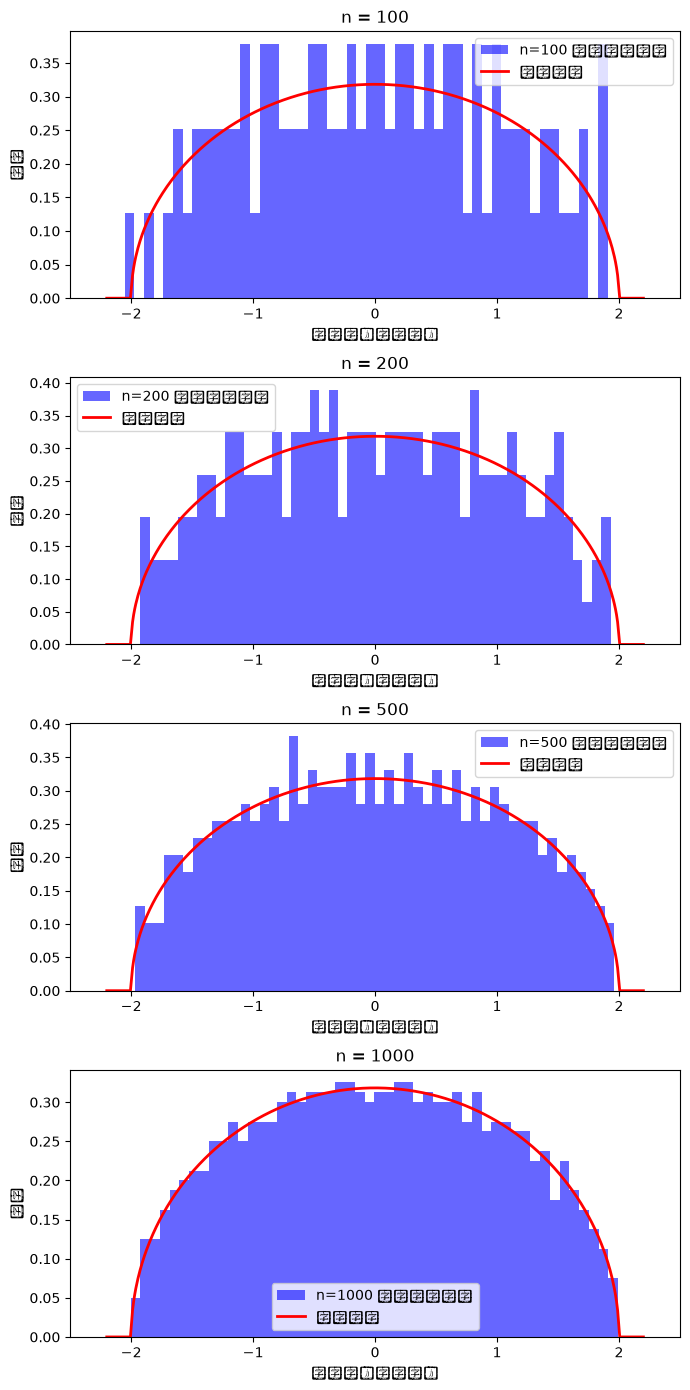

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. wigner_density
def wigner_density(x):
    """半圆密度：|x|<=2 时为 sqrt(4-x^2)/(2*pi)，否则为 0。"""
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    inside = np.abs(x) <= 2
    out[inside] = np.sqrt(4 - x[inside] ** 2) / (2 * np.pi)
    # 若输入为标量，返回 Python float
    if out.ndim == 0:
        return float(out)
    return out

# 2. generate_wigner
def generate_wigner(n):
    """生成 n×n Wigner 矩阵：上三角独立 N(0,1/n)，对称化。"""
    if not isinstance(n, (int, np.integer)) or isinstance(n, bool) or n <= 0:
        raise ValueError("n 必须为正整数")
    # 生成上三角（含对角线）的随机数
    z = np.random.normal(0, 1.0 / np.sqrt(n), size=(n, n))
    # 取上三角，并把严格下三角置为对称位置
    upper = np.triu(z)
    Z = upper + upper.T - np.diag(np.diag(upper))
    return Z

# 3. get_spectrum
def get_spectrum(matrix):
    """返回非递减排序的特征值数组。"""
    vals = np.linalg.eigvalsh(np.asarray(matrix))
    return np.sort(vals)

# 4. 四个纵向子图
np.random.seed(42)  # 可复现
ns = [100, 200, 500, 1000]

fig, axes = plt.subplots(4, 1, figsize=(7, 14))
for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    eig = get_spectrum(Z)

    # 标准化直方图（密度）
    ax.hist(eig, bins=50, density=True, color="blue", alpha=0.6,
            label=f"n={n} 特征值直方图")

    # 半圆密度曲线
    xs = np.linspace(-2.2, 2.2, 500)
    ax.plot(xs, wigner_density(xs), color="red", lw=2, label="半圆密度")

    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.5, 2.5)
    ax.set_xlabel("特征值（标准化）")
    ax.set_ylabel("密度")
    ax.legend()

plt.tight_layout()
plt.show()

## 2.Conway 的生命游戏

有效棋盘: True


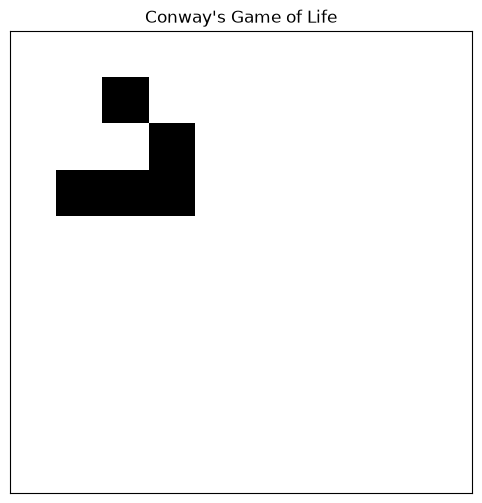

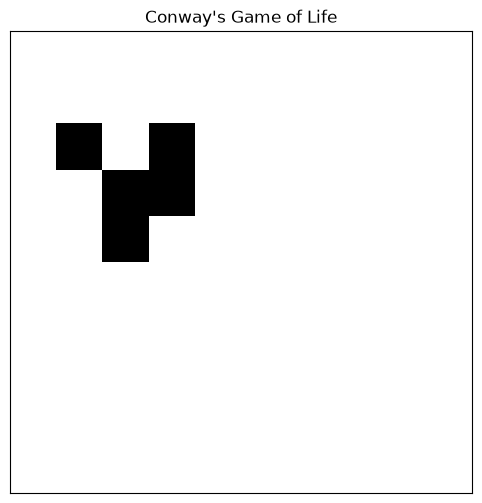

异常: 无效棋盘：必须是二维 ndarray 且元素仅为 0/1


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. is_valid_board
def is_valid_board(board):
    """有效棋盘：二维 ndarray，元素仅为 0 或 1，返回 Python bool。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if board.size == 0:
        return False
    if not np.all((board == 0) | (board == 1)):
        return False
    return True

# 2. gol_step
def gol_step(board):
    """按环绕边界计算下一代棋盘。"""
    if not is_valid_board(board):
        raise ValueError("无效棋盘：必须是二维 ndarray 且元素仅为 0/1")

    m, n = board.shape
    # 用 roll 累加八个邻居（环绕边界）
    neighbors = np.zeros_like(board, dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)

    new_board = np.zeros_like(board)
    # 活细胞：2 或 3 个邻居存活
    survive = (board == 1) & ((neighbors == 2) | (neighbors == 3))
    # 死细胞：恰好 3 个邻居复活
    birth = (board == 0) & (neighbors == 3)
    new_board[survive | birth] = 1
    return new_board

# 3. draw_gol_board
def draw_gol_board(board):
    """活细胞黑色，死细胞白色；无网格线/轴标签/刻度。"""
    if not is_valid_board(board):
        raise ValueError("无效棋盘")
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(board, cmap=plt.get_cmap("gray_r"), interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(False)
    ax.set_title("Conway's Game of Life")
    plt.show()


# ---------- 简单演示 ----------
# 滑翔机（glider）
glider = np.zeros((10, 10), dtype=int)
glider[1, 2] = 1
glider[2, 3] = 1
glider[3, 1] = 1
glider[3, 2] = 1
glider[3, 3] = 1

print("有效棋盘:", is_valid_board(glider))
draw_gol_board(glider)

next_board = gol_step(glider)
draw_gol_board(next_board)

# 无效棋盘示例
try:
    gol_step(np.array([[0, 2], [1, 0]]))
except ValueError as e:
    print("异常:", e)

## 3.使用 pandas DataFrame

In [1]:
import pandas as pd

# ============================================================
# 1. 读取 iris.csv
# ============================================================
df = pd.read_csv("iris.csv")
print("数据点数量:", len(df))
print("每列数据类型:\n", df.dtypes)
print("列名:", list(df.columns))

# ---------- 自动识别列名 ----------
cols = list(df.columns)
species_col = None
for c in cols:
    if any(k in c.lower() for k in ["species", "variety", "class"]):
        species_col = c
        break
if species_col is None:
    species_col = cols[-1]   # 兜底：取最后一列

def find_col(keywords, fallback_idx):
    for c in cols:
        low = c.lower().replace("_", ".").replace(" ", ".")
        if all(k in low for k in keywords):
            return c
    return cols[fallback_idx]

sepal_len_col = find_col(["sepal", "length"], 0)
sepal_wid_col = find_col(["sepal", "width"], 1)
petal_len_col = find_col(["petal", "length"], 2)
petal_wid_col = find_col(["petal", "width"], 3)

print("识别到的列:", species_col, sepal_len_col, sepal_wid_col,
      petal_len_col, petal_wid_col)
print("花卉种类:", df[species_col].unique())
print("花卉种类数:", df[species_col].nunique())

# ============================================================
# 2. 修正第 35、38 行（索引 34、37）
# ============================================================
# 先把四个测量列转成 float，避免 int64 列写小数报错
num_cols = [sepal_len_col, sepal_wid_col, petal_len_col, petal_wid_col]
df[num_cols] = df[num_cols].astype(float)

# 按列名逐列赋值，避免 iloc 整行赋值时的 dtype 冲突
row35 = {
    sepal_len_col: 4.9,
    sepal_wid_col: 3.1,
    petal_len_col: 1.5,
    petal_wid_col: 0.2,
    species_col: "setosa",
}
row38 = {
    sepal_len_col: 4.9,
    sepal_wid_col: 3.6,
    petal_len_col: 1.4,
    petal_wid_col: 0.1,
    species_col: "setosa",
}

for col, val in row35.items():
    df.loc[34, col] = val
for col, val in row38.items():
    df.loc[37, col] = val

print("\n修改后的第 35 行（索引 34）:")
print(df.loc[34])
print("\n修改后的第 38 行（索引 37）:")
print(df.loc[37])

# ============================================================
# 3. 添加两列新特征
# ============================================================
df["Petal.Ratio"] = df[petal_len_col] / df[petal_wid_col]
df["Sepal.Ratio"] = df[sepal_len_col] / df[sepal_wid_col]

# ============================================================
# 4. 保存为 iris_corrected.csv
# ============================================================
df.to_csv("iris_corrected.csv", index=False)
print("\n已保存 iris_corrected.csv")

# ============================================================
# 5. 按花卉种类分组汇总
# ============================================================
summary = df.groupby(species_col)[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print("\n按种类分组统计:")
print(summary)

数据点数量: 150
每列数据类型:
 Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object
列名: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
识别到的列: Species SepalLengthCm SepalWidthCm PetalLengthCm PetalWidthCm
花卉种类: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str
花卉种类数: 3

修改后的第 35 行（索引 34）:
Id                   35
SepalLengthCm       4.9
SepalWidthCm        3.1
PetalLengthCm       1.5
PetalWidthCm        0.2
Species          setosa
Name: 34, dtype: object

修改后的第 38 行（索引 37）:
Id                   38
SepalLengthCm       4.9
SepalWidthCm        3.6
PetalLengthCm       1.4
PetalWidthCm        0.1
Species          setosa
Name: 37, dtype: object

已保存 iris_corrected.csv

按种类分组统计:
                Petal.Ratio                                      Sepal.Ratio  \
                       mean     median       min   max       std 